In [50]:
import pandas as pd
from glob import glob
import seaborn as sns
import aquarel
import matplotlib.pyplot as plt

In [51]:
import ir_datasets

topics_19 = (
    pd.DataFrame(ir_datasets.load("msmarco-passage/trec-dl-2019/judged").qrels_iter())
    .assign(relevance=lambda df: df["relevance"] > 0)
    .loc[:, ["query_id", "relevance"]]
    .groupby("query_id")
    .sum()
    .query("relevance > 50")
    .index
    .tolist()
)

topics_20 = (
    pd.DataFrame(ir_datasets.load("msmarco-passage/trec-dl-2020/judged").qrels_iter())
    .assign(relevance=lambda df: df["relevance"] > 0)
    .loc[:, ["query_id", "relevance"]]
    .groupby("query_id")
    .sum()
    .query("relevance > 50")
    .index
    .tolist()
)

topics_robust = ["301", "304", "306", "307", "311", "318", "319", "321", "324", "343", "352", "353", "354", "357", "360", "367", "370", "374", "383", "389", "390", "391", "392", "395", "398", "399", "400", "404", "408", "412", "415", "418", "422", "424", "425", "431", "434", "435", "436", "438", "439", "443", "450", "631", "656", "683", "688", "700"]

In [52]:
TOPICS = topics_19 + topics_20 + topics_robust

In [53]:
data = []
for f in glob("../data/interim/logs_shallow/*/version_*/metrics.csv"):
    version = f.split("/")[-2].split("_")[-1]
    model, topic = f.split("/")[-3].rsplit("-", 1)
    model_type, model_name = model.split("-", 1)
    model_name, tuning_type = model_name.rsplit("-", 1)
    tmp = (
        pd.read_csv(f)
        .assign(
            model_type=model_type,
            model_name=model_name,
            topic=topic,
            tuning_type=tuning_type,
            version=version,
        )
    )
    try:
        data.append(tmp.loc[:, ["model_type", "model_name", "topic", "tuning_type", "version", "precision", "recall", "accuracy", "f1"]])
    except:
        pass

def get_dataset(topic):
    if topic in topics_19:
        return "trec-dl19"
    elif topic in topics_20:
        return "trec-dl20"
    elif topic in topics_robust:
        return "trec-robust04"
    else:
        return None

df_metrics = (
    pd.concat(data)
    .dropna(subset=["precision", "recall", "accuracy", "f1"])
    .astype({"topic": str})
    .query("topic in @TOPICS")
    .query("version in ['0', '1', '2', '3']")
    .assign(
        depth=lambda df: df["version"].replace({
            "0": 64,
            "1": 128,
            "2": 192,
            "3": 256,
        }),
        dataset=lambda df: df.apply(lambda row: get_dataset(row["topic"]), axis=1)
    )
    .drop(columns=["version"])
    #.dropna(subset=["dataset"])
)

/var/folders/54/8lplw84d1sbgcm1wmd2rgyd40000gn/T/ipykernel_73552/1148589316.py:39: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  depth=lambda df: df["version"].replace({


In [54]:
df_metrics

,model_type,model_name,topic,tuning_type,precision,recall,accuracy,f1,depth,dataset
26,mono,monot5-base-msmarco-10k,359349,lora,1.000000,0.760417,0.846667,0.863905,128,trec-dl19
25,mono,monot5-base-msmarco-10k,359349,lora,0.817204,0.730769,0.789720,0.771574,64,trec-dl19
26,mono,monot5-base-msmarco-10k,359349,lora,1.000000,0.863636,0.863636,0.926829,192,trec-dl19
26,mono,monot5-base-msmarco-10k,330975,lora,0.925000,0.711538,0.858268,0.804348,128,trec-dl20
25,mono,monot5-base-msmarco-10k,330975,lora,0.769231,0.803571,0.845912,0.786026,64,trec-dl20
...,...,...,...,...,...,...,...,...,...,...
10,mono,monot5-base-msmarco-10k,392,lora,0.232727,0.876712,0.787234,0.367816,256,trec-robust04
10,mono,monot5-base-msmarco-10k,357,lora,0.282675,0.732283,0.637827,0.407895,128,trec-robust04
10,mono,monot5-base-msmarco-10k,357,lora,0.227652,0.729008,0.537621,0.346957,64,trec-robust04
10,mono,monot5-base-msmarco-10k,357,lora,0.321224,0.682927,0.696566,0.436931,192,trec-robust04


In [55]:
df_metrics.loc[:, ["depth", "topic", "precision", "recall", "accuracy", "f1"]]

,depth,topic,precision,recall,accuracy,f1
26,128,359349,1.000000,0.760417,0.846667,0.863905
25,64,359349,0.817204,0.730769,0.789720,0.771574
26,192,359349,1.000000,0.863636,0.863636,0.926829
26,128,330975,0.925000,0.711538,0.858268,0.804348
25,64,330975,0.769231,0.803571,0.845912,0.786026
...,...,...,...,...,...,...
10,256,392,0.232727,0.876712,0.787234,0.367816
10,128,357,0.282675,0.732283,0.637827,0.407895
10,64,357,0.227652,0.729008,0.537621,0.346957
10,192,357,0.321224,0.682927,0.696566,0.436931


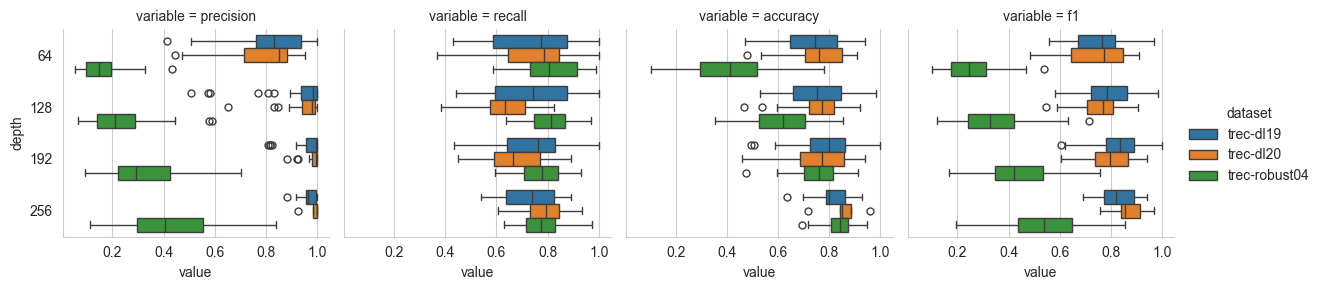

In [64]:
g = sns.catplot(
    data=(
        df_metrics
        .loc[:, ["depth", "topic", "dataset", "precision", "recall", "accuracy", "f1"]]
        .astype({"depth": str})
        .melt(id_vars=["depth", "topic", "dataset"])
    ),
    x="value",
    y="depth",
    hue="dataset",
    col="variable",
    kind="box",
    order=["64", "128", "192", "256"],
     aspect=1, height=3, sharex=True, legend_out=True,
)
g.savefig("figure-eval-shallow.pdf")


In [120]:
print(
    pd.concat([
        pd.read_parquet(f).assign(train_size=f.split("/")[-1].split("-")[-1].split(".")[0])
        for f in glob("../data/processed/*-shallow-qrels-*.parquet")
    ])
    .astype({"query_id": str, "doc_id": str})
    .merge(
        pd.concat([
            pd.DataFrame(ir_datasets.load("disks45/nocr/trec-robust-2004").qrels_iter()).astype({"query_id": str, "doc_id": str}).assign(dataset="robust04"),
            pd.DataFrame(ir_datasets.load("msmarco-passage/trec-dl-2019/judged").qrels_iter()).astype({"query_id": str, "doc_id": str}).assign(dataset="dl19"),
            pd.DataFrame(ir_datasets.load("msmarco-passage/trec-dl-2020/judged").qrels_iter()).astype({"query_id": str, "doc_id": str}).assign(dataset="dl20"),
        ]),
        on=["query_id", "doc_id"],
        how="left",
    )
    .drop(columns=["iteration", "doc_id"])
    .assign(relevance_x=lambda df: df["relevance_x"] > 0.5, relevance_y=lambda df: df["relevance_y"] > 0)
    .groupby(["dataset", "train_size", "query_id"])
    .apply(lambda group: pd.crosstab(group["relevance_x"], group["relevance_y"], normalize="all"))
    .reset_index()
    .drop(columns=["query_id"])
    .groupby(["dataset", "train_size", "relevance_x"])
    .mean()
    .reset_index()
    .melt(id_vars=["dataset", "train_size", "relevance_x"])
    .pivot(index=["train_size", "relevance_x"], columns=["dataset", "relevance_y"], values="value")
    .iloc[
        [6,7,0,1,2,3,4,5],
        [0,3,1,4,2,5]
    ]
    .to_latex()
)

\begin{tabular}{llrrrrrr}
\toprule
 & dataset & \multicolumn{2}{r}{dl19} & \multicolumn{2}{r}{dl20} & \multicolumn{2}{r}{robust04} \\
 & relevance_y & False & True & False & True & False & True \\
train_size & relevance_x &  &  &  &  &  &  \\
\midrule
\multirow[t]{2}{*}{64} & False & 0.471886 & 0.123273 & 0.593409 & 0.087053 & 0.308690 & 0.021646 \\
 & True & 0.072317 & 0.343377 & 0.080152 & 0.251941 & 0.567379 & 0.102285 \\
\cline{1-8}
\multirow[t]{2}{*}{128} & False & 0.466686 & 0.159924 & 0.627576 & 0.140632 & 0.516097 & 0.024643 \\
 & True & 0.006266 & 0.391083 & 0.013040 & 0.260836 & 0.359514 & 0.099747 \\
\cline{1-8}
\multirow[t]{2}{*}{192} & False & 0.479565 & 0.167301 & 0.598957 & 0.154389 & 0.657898 & 0.027329 \\
 & True & 0.002480 & 0.521208 & 0.005099 & 0.363717 & 0.217114 & 0.097659 \\
\cline{1-8}
\multirow[t]{2}{*}{256} & False & 0.443202 & 0.144893 & 0.562910 & 0.129965 & 0.742830 & 0.028938 \\
 & True & 0.001605 & 0.707571 & 0.002084 & 0.505458 & 0.131383 & 0.096849 \\
\

/var/folders/54/8lplw84d1sbgcm1wmd2rgyd40000gn/T/ipykernel_73552/3387537396.py:19: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: pd.crosstab(group["relevance_x"], group["relevance_y"], normalize="all"))
